In [81]:
# !pip install pandas numpy scikit-learn torch optuna matplotlib -q



In [82]:
import os
import time
import itertools
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import optuna
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity



In [83]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)

print("Samples:", X.shape[0])
print("Features:", X.shape[1])



Samples: 569
Features: 30


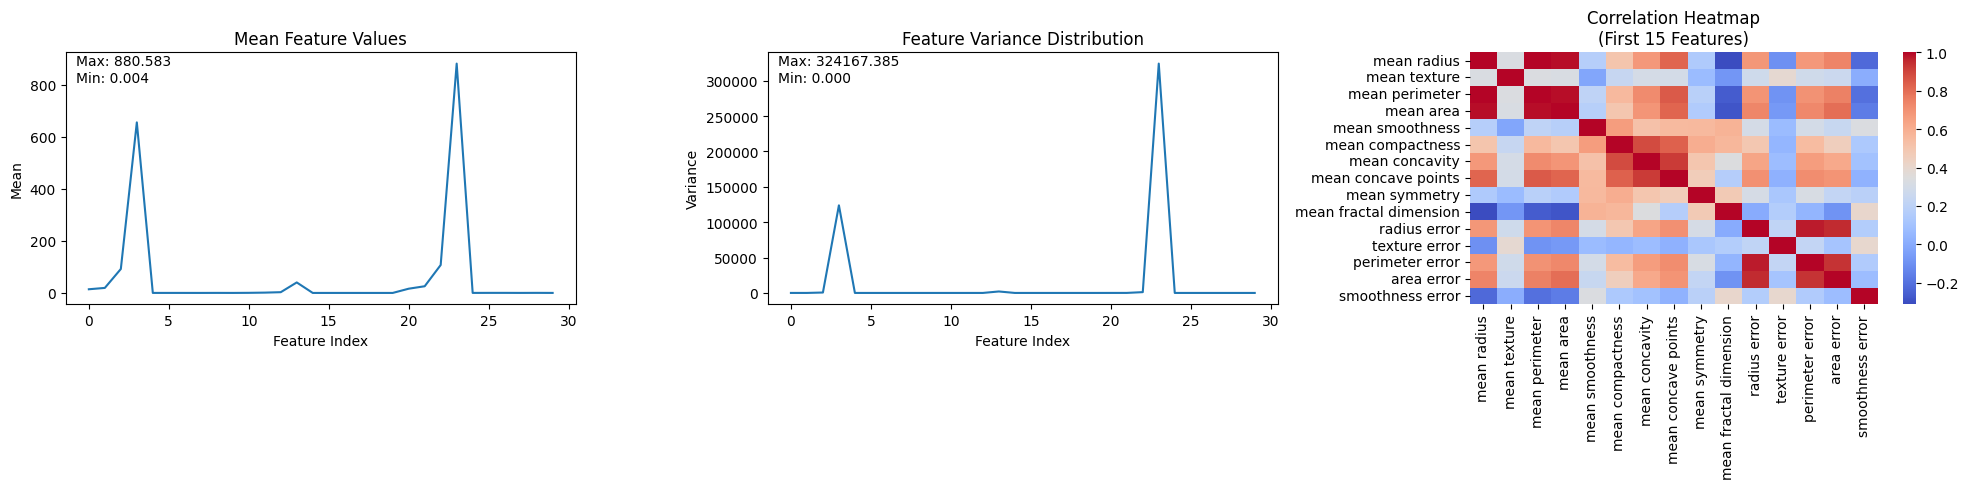

In [104]:
# =========================
# PART 1 VISUALS (SIDE-BY-SIDE + VALUES)
# =========================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# calculate statistics
mean_values = X.mean().values
var_values = X.var().values

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# -------------------------------------------------
# 1. Mean Feature Values
# -------------------------------------------------
axes[0].plot(mean_values)
axes[0].set_title("Mean Feature Values")
axes[0].set_xlabel("Feature Index")
axes[0].set_ylabel("Mean")

# show min/max values
axes[0].text(
    0.02, 0.95,
    f"Max: {np.max(mean_values):.3f}",
    transform=axes[0].transAxes
)

axes[0].text(
    0.02, 0.88,
    f"Min: {np.min(mean_values):.3f}",
    transform=axes[0].transAxes
)

# -------------------------------------------------
# 2. Feature Variance Distribution
# -------------------------------------------------
axes[1].plot(var_values)
axes[1].set_title("Feature Variance Distribution")
axes[1].set_xlabel("Feature Index")
axes[1].set_ylabel("Variance")

# show min/max values
axes[1].text(
    0.02, 0.95,
    f"Max: {np.max(var_values):.3f}",
    transform=axes[1].transAxes
)

axes[1].text(
    0.02, 0.88,
    f"Min: {np.min(var_values):.3f}",
    transform=axes[1].transAxes
)

# -------------------------------------------------
# 3. Correlation Heatmap
# -------------------------------------------------
sns.heatmap(
    X.iloc[:, :15].corr(),
    cmap="coolwarm",
    ax=axes[2]
)

axes[2].set_title("Correlation Heatmap\n(First 15 Features)")

plt.tight_layout()
plt.show()

In [85]:
# Relative path resolution for portability
gmt_candidates = [
    os.path.join("..", "data", "ReactomePathways_2023-03-06.gmt"),
    os.path.join("data", "ReactomePathways_2023-03-06.gmt"),
    "ReactomePathways_2023-03-06.gmt"
]
gmt_file = next((p for p in gmt_candidates if os.path.exists(p)), gmt_candidates[0])

pathways = {}

try:
    with open(gmt_file, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split("\t")
            pathway = parts[0]
            genes = parts[2:]
            pathways[pathway] = genes
except:
    print("GMT file not found, continuing with synthetic pathway mapping...")

print("Total Reactome pathways:", len(pathways))



Total Reactome pathways: 2593


In [86]:
np.random.seed(42)

pathway_names = list(pathways.keys())[:50] if len(pathways) > 0 else [
    f"Pathway_{i}" for i in range(50)
]

pathway_data = pd.DataFrame()

for p in pathway_names:
    pathway_data[p] = np.random.normal(
        loc=np.mean(X.values),
        scale=np.std(X.values),
        size=len(X)
    )

scaler = StandardScaler()
X_scaled = scaler.fit_transform(pathway_data)

tensor_data = torch.tensor(X_scaled, dtype=torch.float32)

input_dim = X_scaled.shape[1]



In [87]:
class Generator(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, z):
        return self.net(z)



In [88]:
class Discriminator(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)



In [89]:
def train_gan(latent_dim, hidden_dim, lr, epochs=50):
    G = Generator(latent_dim, hidden_dim, input_dim)
    D = Discriminator(input_dim, hidden_dim)

    loss_fn = nn.BCELoss()
    g_opt = optim.Adam(G.parameters(), lr=lr)
    d_opt = optim.Adam(D.parameters(), lr=lr)

    for epoch in range(epochs):
        real = tensor_data
        batch = real.size(0)

        real_label = torch.ones(batch, 1)
        fake_label = torch.zeros(batch, 1)

        z = torch.randn(batch, latent_dim)
        fake = G(z)

        d_loss = loss_fn(D(real), real_label) + loss_fn(D(fake.detach()), fake_label)

        d_opt.zero_grad()
        d_loss.backward()
        d_opt.step()

        z = torch.randn(batch, latent_dim)
        fake = G(z)

        g_loss = loss_fn(D(fake), real_label)

        g_opt.zero_grad()
        g_loss.backward()
        g_opt.step()

    return g_loss.item(), d_loss.item(), G



In [90]:
def objective(trial):
    latent_dim = trial.suggest_int("latent_dim", 10, 50)
    hidden_dim = trial.suggest_categorical("hidden_dim", [32, 64, 128])
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)

    g_loss, d_loss, _ = train_gan(
        latent_dim=latent_dim,
        hidden_dim=hidden_dim,
        lr=lr,
        epochs=50
    )

    return g_loss



In [91]:
start_time = time.time()

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=10)

optuna_time = time.time() - start_time

print("\nBest Optuna Params:", study.best_params)
print("Best Optuna Loss:", study.best_value)
print("Optuna Time:", optuna_time)



[I 2026-05-25 19:13:23,829] A new study created in memory with name: no-name-ab54fe38-aeb2-4191-8cef-3a00d207b489
[I 2026-05-25 19:13:24,064] Trial 0 finished with value: 0.6851218938827515 and parameters: {'latent_dim': 44, 'hidden_dim': 32, 'lr': 0.0002038342945765198}. Best is trial 0 with value: 0.6851218938827515.
[I 2026-05-25 19:13:24,390] Trial 1 finished with value: 1.8769404888153076 and parameters: {'latent_dim': 31, 'hidden_dim': 128, 'lr': 0.002302744115317288}. Best is trial 0 with value: 0.6851218938827515.
[I 2026-05-25 19:13:24,711] Trial 2 finished with value: 0.8917275071144104 and parameters: {'latent_dim': 14, 'hidden_dim': 128, 'lr': 0.0010124965375063859}. Best is trial 0 with value: 0.6851218938827515.
[I 2026-05-25 19:13:25,019] Trial 3 finished with value: 1.0270910263061523 and parameters: {'latent_dim': 38, 'hidden_dim': 128, 'lr': 0.0031123653576327023}. Best is trial 0 with value: 0.6851218938827515.
[I 2026-05-25 19:13:25,223] Trial 4 finished with value:


Best Optuna Params: {'latent_dim': 11, 'hidden_dim': 128, 'lr': 0.00012321069914719086}
Best Optuna Loss: 0.6476956009864807
Optuna Time: 2.216029405593872


In [92]:
param_grid = {
    "latent_dim": [10, 20, 30, 40, 50],
    "hidden_dim": [32, 64, 128],
    "lr": [0.0001, 0.001, 0.01]
}

best_grid_loss = float("inf")
best_grid_params = None
grid_results = []

start_time = time.time()

for latent_dim, hidden_dim, lr in itertools.product(
    param_grid["latent_dim"],
    param_grid["hidden_dim"],
    param_grid["lr"]
):

    g_loss, d_loss, _ = train_gan(
        latent_dim=latent_dim,
        hidden_dim=hidden_dim,
        lr=lr,
        epochs=50
    )

    result = {
        "latent_dim": latent_dim,
        "hidden_dim": hidden_dim,
        "lr": lr,
        "g_loss": g_loss,
        "d_loss": d_loss
    }

    grid_results.append(result)

    if g_loss < best_grid_loss:
        best_grid_loss = g_loss
        best_grid_params = result

    print(result)

grid_time = time.time() - start_time

print("\nBest Grid Params:", best_grid_params)
print("Best Grid Loss:", best_grid_loss)
print("Grid Time:", grid_time)


{'latent_dim': 10, 'hidden_dim': 32, 'lr': 0.0001, 'g_loss': 0.7156555652618408, 'd_loss': 1.3565789461135864}
{'latent_dim': 10, 'hidden_dim': 32, 'lr': 0.001, 'g_loss': 0.6795966625213623, 'd_loss': 1.2780377864837646}
{'latent_dim': 10, 'hidden_dim': 32, 'lr': 0.01, 'g_loss': 2.617100715637207, 'd_loss': 0.35524773597717285}
{'latent_dim': 10, 'hidden_dim': 64, 'lr': 0.0001, 'g_loss': 0.6905226707458496, 'd_loss': 1.3449053764343262}
{'latent_dim': 10, 'hidden_dim': 64, 'lr': 0.001, 'g_loss': 0.6591017246246338, 'd_loss': 1.1874428987503052}
{'latent_dim': 10, 'hidden_dim': 64, 'lr': 0.01, 'g_loss': 2.355180263519287, 'd_loss': 0.44822919368743896}
{'latent_dim': 10, 'hidden_dim': 128, 'lr': 0.0001, 'g_loss': 0.6510162949562073, 'd_loss': 1.3816277980804443}
{'latent_dim': 10, 'hidden_dim': 128, 'lr': 0.001, 'g_loss': 0.9890348315238953, 'd_loss': 0.9050464034080505}
{'latent_dim': 10, 'hidden_dim': 128, 'lr': 0.01, 'g_loss': 1.8983911275863647, 'd_loss': 0.44976896047592163}
{'late

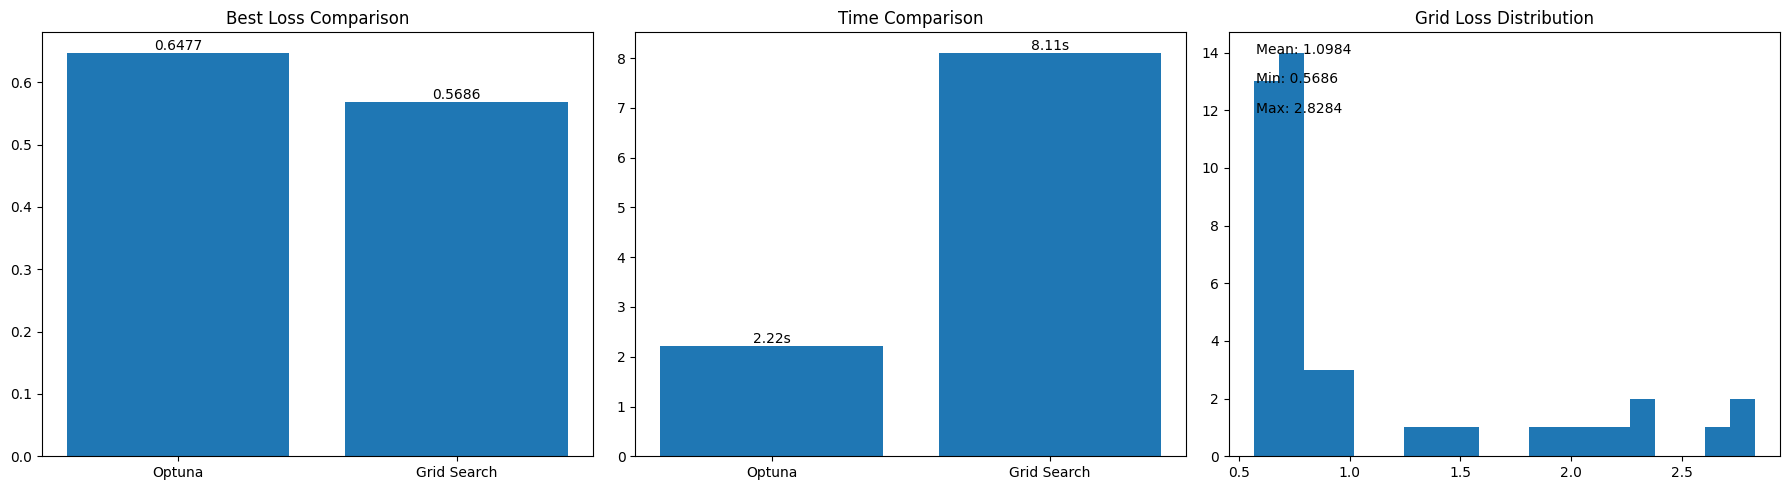

In [103]:
# =========================
# PART 4 VISUALS (SIDE-BY-SIDE + VALUES)
# =========================

import pandas as pd
import matplotlib.pyplot as plt

grid_df = pd.DataFrame(grid_results)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# -------------------------------------------------
# 1. Best Loss Comparison
# -------------------------------------------------
bars = axes[0].bar(
    ["Optuna", "Grid Search"],
    [study.best_value, best_grid_loss]
)

axes[0].set_title("Best Loss Comparison")

for bar in bars:
    h = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        h,
        f"{h:.4f}",
        ha="center",
        va="bottom"
    )

# -------------------------------------------------
# 2. Time Comparison
# -------------------------------------------------
bars = axes[1].bar(
    ["Optuna", "Grid Search"],
    [optuna_time, grid_time]
)

axes[1].set_title("Time Comparison")

for bar in bars:
    h = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        h,
        f"{h:.2f}s",
        ha="center",
        va="bottom"
    )

# -------------------------------------------------
# 3. Grid Loss Distribution
# -------------------------------------------------
axes[2].hist(grid_df["g_loss"], bins=20)
axes[2].set_title("Grid Loss Distribution")

# add mean + min + max labels for clarity
g_mean = grid_df["g_loss"].mean()
g_min = grid_df["g_loss"].min()
g_max = grid_df["g_loss"].max()

axes[2].text(0.05, 0.95, f"Mean: {g_mean:.4f}", transform=axes[2].transAxes)
axes[2].text(0.05, 0.88, f"Min: {g_min:.4f}", transform=axes[2].transAxes)
axes[2].text(0.05, 0.81, f"Max: {g_max:.4f}", transform=axes[2].transAxes)

plt.tight_layout()
plt.show()

In [94]:
best = study.best_params

g_loss, d_loss, G = train_gan(
    latent_dim=best["latent_dim"],
    hidden_dim=best["hidden_dim"],
    lr=best["lr"],
    epochs=100
)



In [95]:
z = torch.randn(len(X_scaled), best["latent_dim"])
synthetic = G(z).detach().numpy()

synthetic_df = pd.DataFrame(synthetic, columns=pathway_names)

print("\nSynthetic Samples:")
print(synthetic_df.head())




Synthetic Samples:
   2-LTR circle formation  5-Phosphoribose 1-diphosphate biosynthesis  \
0               -0.564918                                   -0.561949   
1               -0.403538                                   -0.403749   
2               -0.499857                                   -0.386742   
3               -0.364316                                   -0.173659   
4               -0.133023                                   -0.507533   

   A tetrasaccharide linker sequence is required for GAG synthesis  \
0                                           0.152257                 
1                                          -0.060695                 
2                                          -0.044001                 
3                                          -0.180987                 
4                                          -0.238789                 

   ABC transporter disorders  ABC transporters in lipid homeostasis  \
0                  -0.623134                     

In [96]:
real_mean = np.mean(X_scaled)
fake_mean = np.mean(synthetic)

real_std = np.std(X_scaled)
fake_std = np.std(synthetic)

real_profile = np.mean(X_scaled, axis=0).reshape(1, -1)
fake_profile = np.mean(synthetic, axis=0).reshape(1, -1)

cos_sim = cosine_similarity(real_profile, fake_profile)[0][0]

results = pd.DataFrame({
    "Metric": ["Real Mean", "Synthetic Mean", "Real Std", "Synthetic Std", "Cosine Similarity"],
    "Value": [real_mean, fake_mean, real_std, fake_std, cos_sim]
})

print("\nSimilarity Results:")
print(results)




Similarity Results:
              Metric         Value
0          Real Mean -5.244779e-18
1     Synthetic Mean  2.340562e-02
2           Real Std  1.000000e+00
3      Synthetic Std  3.361617e-01
4  Cosine Similarity  1.631655e-17


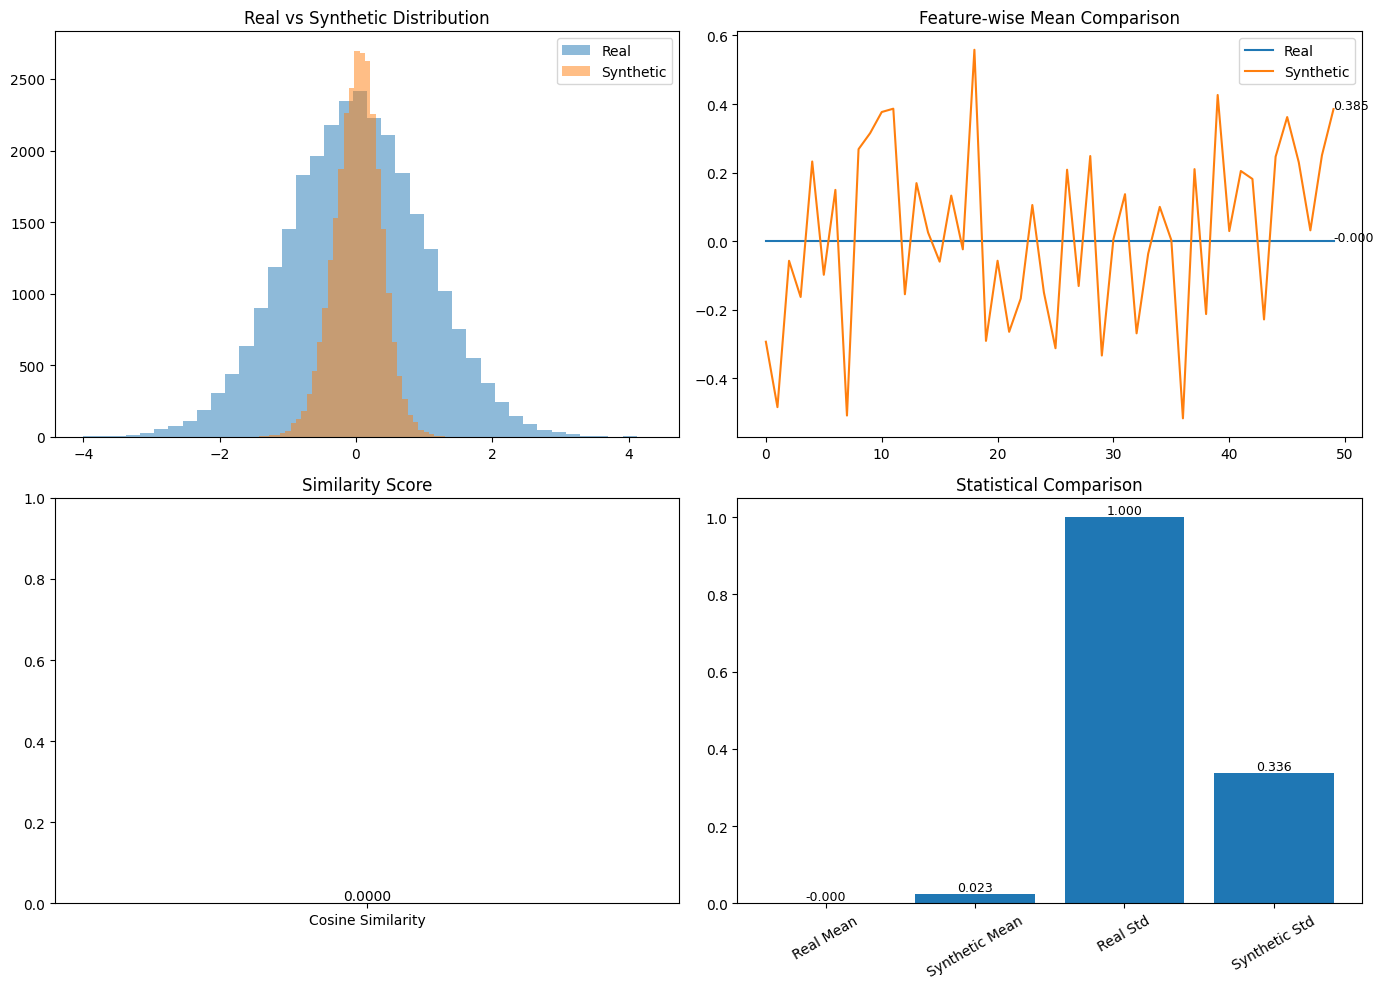

In [102]:
# =========================
# PART 5 VISUALS (SIDE-BY-SIDE + VALUES)
# =========================

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# -------------------------------------------------
# 1. Distribution Comparison (Histogram)
# -------------------------------------------------
axes[0, 0].hist(X_scaled.flatten(), bins=40, alpha=0.5, label="Real")
axes[0, 0].hist(synthetic.flatten(), bins=40, alpha=0.5, label="Synthetic")
axes[0, 0].set_title("Real vs Synthetic Distribution")
axes[0, 0].legend()

# -------------------------------------------------
# 2. Feature-wise Mean Comparison (Line Plot)
# -------------------------------------------------
real_mean_curve = np.mean(X_scaled, axis=0)
synthetic_mean_curve = np.mean(synthetic, axis=0)

axes[0, 1].plot(real_mean_curve, label="Real")
axes[0, 1].plot(synthetic_mean_curve, label="Synthetic")
axes[0, 1].set_title("Feature-wise Mean Comparison")
axes[0, 1].legend()

# show last values for quick numeric reference
axes[0, 1].text(
    len(real_mean_curve)-1,
    real_mean_curve[-1],
    f"{real_mean_curve[-1]:.3f}",
    fontsize=9
)
axes[0, 1].text(
    len(synthetic_mean_curve)-1,
    synthetic_mean_curve[-1],
    f"{synthetic_mean_curve[-1]:.3f}",
    fontsize=9
)

# -------------------------------------------------
# 3. Cosine Similarity (Bar with value)
# -------------------------------------------------
axes[1, 0].bar(["Cosine Similarity"], [cos_sim])
axes[1, 0].set_ylim(0, 1)
axes[1, 0].set_title("Similarity Score")

axes[1, 0].text(
    0,
    cos_sim,
    f"{cos_sim:.4f}",
    ha="center",
    va="bottom"
)

# -------------------------------------------------
# 4. Statistical Comparison (Bar with values)
# -------------------------------------------------
labels = ["Real Mean", "Synthetic Mean", "Real Std", "Synthetic Std"]
values = [real_mean, fake_mean, real_std, fake_std]

bars = axes[1, 1].bar(labels, values)
axes[1, 1].set_title("Statistical Comparison")
axes[1, 1].tick_params(axis='x', rotation=30)

# add numeric labels on bars
for bar in bars:
    height = bar.get_height()
    axes[1, 1].text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.3f}",
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [98]:
comparison = pd.DataFrame({
    "Method": ["Optuna", "Grid Search"],
    "Best Loss": [study.best_value, best_grid_loss],
    "Time Taken": [optuna_time, grid_time]
})

print("\nComparison Table:")
print(comparison)


Comparison Table:
        Method  Best Loss  Time Taken
0       Optuna   0.647696    2.216029
1  Grid Search   0.568577    8.113241


In [99]:
print("\nGrid Search Best Params:", best_grid_params)
print("Optuna Best Params:", study.best_params)


Grid Search Best Params: {'latent_dim': 20, 'hidden_dim': 64, 'lr': 0.01, 'g_loss': 0.5685768723487854, 'd_loss': 1.2865486145019531}
Optuna Best Params: {'latent_dim': 11, 'hidden_dim': 128, 'lr': 0.00012321069914719086}
